# 10 - Regressão
Vamos aprender sobre como usar técnicas de ajuste de curvas que buscam modelar a relação entre variáveis, como o método dos mínimos quadrados, para estimar os coeficientes da equação.

Crie uma nova branch (versão) do repositório:

```bash
git branch semana10
```

Faça o checkout nessa nova branch:

```bash
git checkout semana10
```

<hr />

## Atividade 1
Escreva o método de regressão por quadrado mínimo dentro do arquivo $utils/algoritmos.py$.

In [1]:
import numpy as np

def regressao(x, y, v):
    V = v(x)
    Vt = V.T
    A = np.linalg.inv(Vt @ V) @ (Vt @ y)
    return A

Seja dado o conjunto de pontos  
$\{(-0.35, 0.2),\ (0.15, -0.5),\ (0.23, 0.54),\ (0.35, 0.7)\}$.

Encontre a função linear $f(x) = a_1 + a_2x$ que melhor se ajusta aos pontos dados no **sentido dos mínimos quadrados**.  
Em seguida, desenhe um gráfico com os pontos e o esboço da função ajustada.

**Resposta esperada:**

$$
f(x) = -0.47x + 0.19
$$

[0.18992262 0.47449877]


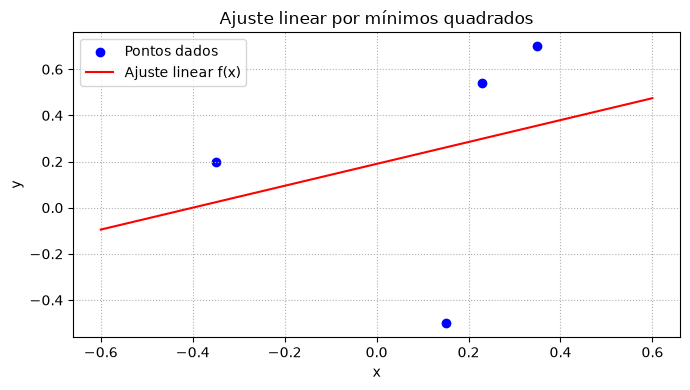

In [2]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Sobe um nível para a raiz do projeto e adiciona ao caminho do sistema
sys.path.append(os.path.abspath(os.path.join('..')))

from utils.algoritmos import (
    regressao,
)


def plot(x, y, v):
    x_vals = np.linspace(min(x) - 0.25, max(x) + 0.25, 400)
    y_vals = np.zeros_like(x_vals, dtype=float)
    A = regressao(x, y, v)
    for p, ap in enumerate(A):
        y_vals += ap * (x_vals**p)
    plt.figure(figsize=(7, 4))
    plt.scatter(x, y, color="blue", label="Pontos dados")
    plt.plot(x_vals, y_vals, color="red", label="Ajuste linear f(x)")
    plt.title("Ajuste linear por mínimos quadrados")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.grid(True, linestyle=":")
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.close()


def main():
    x = np.array([-0.35, 0.15, 0.23, 0.35], dtype=float)
    y = np.array([0.20, -0.50, 0.54, 0.70], dtype=float)
    v = lambda x: np.column_stack((np.ones(len(x)), x))

    A = regressao(x, y, v)

    print(A)
    plot(x, y, v)

if __name__ == "__main__":
    main()

## Atividade 2
Seja dado o conjunto de pontos  
$\{(-1.94,\,1.02),\ (-1.44,\,0.59),\ (0.93,\,-0.28),\ (1.39,\,-1.04)\}$.

Encontre a função linear $f(x) = a_1 + a_2x$ que melhor se ajusta aos pontos dados no sentido dos **mínimos quadrados**. Encontre o valor de $f(1)$. Em seguida, desenhe um gráfico com os pontos e o esboço da função ajustada.

**Resposta esperada:**

$$
f(x) = -0.06891127x -0.53362743 
$$

$$
f(1) = -0.6025387
$$

Coeficientes [a1, a2]: [-0.06891127 -0.53362743]
f(x) = -0.53362743x + (-0.06891127)
f(1) = -0.6025387


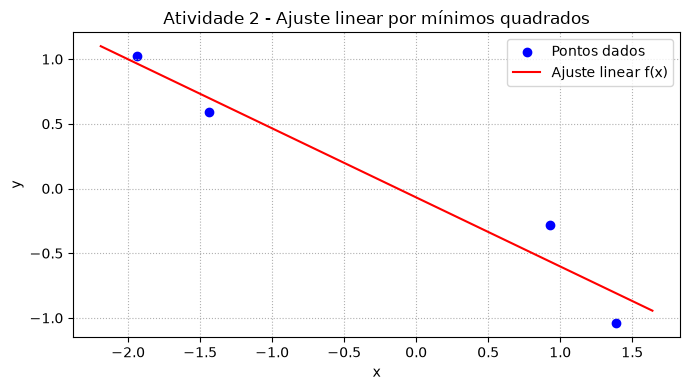

In [3]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join('..')))
from utils.algoritmos import regressao

def plot_atv2(x, y, A):
    x_vals = np.linspace(min(x) - 0.25, max(x) + 0.25, 400)
    y_vals = A[0] + A[1] * x_vals
    
    plt.figure(figsize=(7, 4))
    plt.scatter(x, y, color="blue", label="Pontos dados")
    plt.plot(x_vals, y_vals, color="red", label="Ajuste linear f(x)")
    plt.title("Atividade 2 - Ajuste linear por mínimos quadrados")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.grid(True, linestyle=":")
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.close()

def main_atv2():
    x = np.array([-1.94, -1.44, 0.93, 1.39], dtype=float)
    y = np.array([1.02, 0.59, -0.28, -1.04], dtype=float)
    
    # Matriz de Vandermonde / base [1, x]
    v = lambda x: np.column_stack((np.ones(len(x)), x))
    
    A = regressao(x, y, v)
    f_1 = A[0] + A[1] * 1.0
    
    print(f"Coeficientes [a1, a2]: {A}")
    print(f"f(x) = {A[1]:.8f}x + ({A[0]:.8f})")
    print(f"f(1) = {f_1:.7f}")
    
    plot_atv2(x, y, A)

if __name__ == "__main__":
    main_atv2()

## Atividade 3
Encontrar a parábola $y = ax^2 + bx + c$ que melhor aproxima o seguinte conjunto de dados:

| $i$ | 1 | 2 | 3 | 4 | 5 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| $x_i$ | 0.01 | 1.02 | 2.04 | 2.95 | 3.55 |
| $y_i$ | 1.99 | 4.55 | 7.20 | 9.51 | 10.82 |

**Resposta esperada:**

$$
y = -0.0407898x^2 + 2.6613293x + 1.9364598
$$

Coeficientes [a, b, c]: [-0.04078983  2.66132929  1.93645978]
y = -0.0407898x^2 + 2.6613293x + 1.9364598


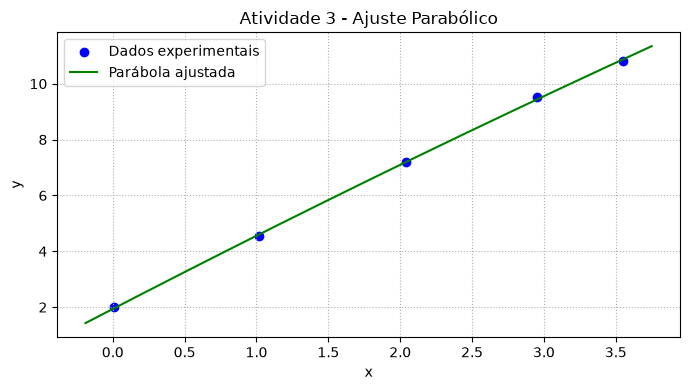

In [4]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join('..')))
from utils.algoritmos import regressao

def main_atv3():
    x = np.array([0.01, 1.02, 2.04, 2.95, 3.55], dtype=float)
    y = np.array([1.99, 4.55, 7.20, 9.51, 10.82], dtype=float)
    
    # Base polinomial [x^2, x, 1] para retornar diretamente [a, b, c]
    v = lambda x: np.column_stack((x**2, x, np.ones(len(x))))
    
    A = regressao(x, y, v)
    a, b, c = A
    
    print(f"Coeficientes [a, b, c]: {A}")
    print(f"y = {a:.7f}x^2 + {b:.7f}x + {c:.7f}")
    
    # Gráfico opcional para visualização
    x_vals = np.linspace(min(x) - 0.2, max(x) + 0.2, 400)
    y_vals = a * (x_vals**2) + b * x_vals + c
    
    plt.figure(figsize=(7, 4))
    plt.scatter(x, y, color="blue", label="Dados experimentais")
    plt.plot(x_vals, y_vals, color="green", label="Parábola ajustada")
    plt.title("Atividade 3 - Ajuste Parabólico")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.grid(True, linestyle=":")
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.close()

if __name__ == "__main__":
    main_atv3()

## Atividade 4
Dado o seguinte conjunto de dados:

| $x_i$ | 0.0 | 0.1 | 0.2 | 0.3 | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 | 1.0 |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $y_i$ | 31 | 35 | 37 | 33 | 28 | 20 | 16 | 15 | 18 | 23 | 31 |

**a)** Encontre a função do tipo  
$f(x) = a + b \sin(2\pi x) + c \cos(2\pi x)$  
que melhor aproxima os valores dados.

**b)** Encontre a função do tipo  
$f(x) = a + bx + cx^2 + dx^3$  
que melhor aproxima os valores dados.

**Respostas esperadas:**

$$
\text{a)}\quad a = 25.638625,\quad b = 9.8591874,\quad c = 4.9751219
$$

$$
\text{b)}\quad a = 31.475524,\quad b = 65.691531,\quad c = -272.84382,\quad d = 208.23621
$$

a) a = 25.638625, b = 9.8591874, c = 4.9751219
b) a = 31.475524, b = 65.691531, c = -272.84382, d = 208.23621


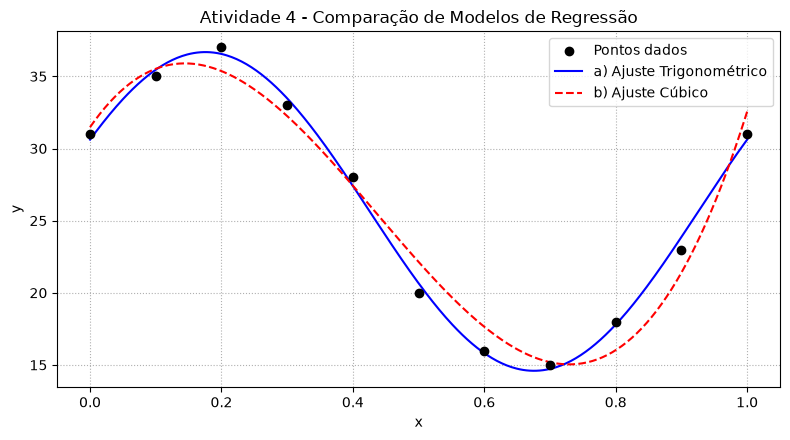

In [5]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join('..')))
from utils.algoritmos import regressao

def main_atv4():
    x = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], dtype=float)
    y = np.array([31, 35, 37, 33, 28, 20, 16, 15, 18, 23, 31], dtype=float)
    
    # --- Item (a): f(x) = a + b*sin(2*pi*x) + c*cos(2*pi*x) ---
    v_trig = lambda x: np.column_stack((
        np.ones(len(x)),
        np.sin(2 * np.pi * x),
        np.cos(2 * np.pi * x)
    ))
    A_trig = regressao(x, y, v_trig)
    print(f"a) a = {A_trig[0]:.6f}, b = {A_trig[1]:.7f}, c = {A_trig[2]:.7f}")
    
    # --- Item (b): f(x) = a + b*x + c*x^2 + d*x^3 ---
    v_cub = lambda x: np.column_stack((
        np.ones(len(x)),
        x,
        x**2,
        x**3
    ))
    A_cub = regressao(x, y, v_cub)
    print(f"b) a = {A_cub[0]:.6f}, b = {A_cub[1]:.6f}, c = {A_cub[2]:.5f}, d = {A_cub[3]:.5f}")
    
    # Gráfico comparativo dos dois ajustes
    x_vals = np.linspace(0, 1, 400)
    y_trig = A_trig[0] + A_trig[1] * np.sin(2 * np.pi * x_vals) + A_trig[2] * np.cos(2 * np.pi * x_vals)
    y_cub = A_cub[0] + A_cub[1] * x_vals + A_cub[2] * (x_vals**2) + A_cub[3] * (x_vals**3)
    
    plt.figure(figsize=(8, 4.5))
    plt.scatter(x, y, color="black", label="Pontos dados", zorder=5)
    plt.plot(x_vals, y_trig, color="blue", label="a) Ajuste Trigonométrico")
    plt.plot(x_vals, y_cub, color="red", linestyle="--", label="b) Ajuste Cúbico")
    plt.title("Atividade 4 - Comparação de Modelos de Regressão")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.grid(True, linestyle=":")
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.close()

if __name__ == "__main__":
    main_atv4()

## Versionando o código

Submeta a branch para o servidor:

```bash
git add .
git commit -m "Semana 10"
git push origin semana10
```